In [1]:
import sys

print("Python version:")
print(sys.version)

print("\nPython environment:")
print(sys.executable)

import geopandas as gpd
import rasterio
import rioxarray
import shapely
import pyproj
import pandas as pd
import numpy as np
import matplotlib
import folium

print("\nGIS packages loaded successfully.")
print("GeoPandas:", gpd.__version__)
print("Rasterio:", rasterio.__version__)
print("Shapely:", shapely.__version__)
print("PyProj:", pyproj.__version__) 

Python version:
3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:14:50) [MSC v.1942 64 bit (AMD64)]

Python environment:
C:\Users\Lioness_eni\anaconda3\envs\epe_atlas\python.exe

GIS packages loaded successfully.
GeoPandas: 1.2.0
Rasterio: 1.5.0
Shapely: 2.1.2
PyProj: 3.7.2


In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

print("Ready for spatial analysis.")

Ready for spatial analysis.


In [4]:
from pathlib import Path

project = Path.cwd()

print("Current project folder:")
print(project)

print("\nContents:")
for item in project.iterdir():
    print(item.name)

Current project folder:
C:\Users\Lioness_eni\Epe_Coastal_Atlas

Contents:
.ipynb_checkpoints
01_Epe_Study_Area.ipynb
data
documentation
notebooks
outputs
scripts


In [7]:
import requests

layer_url = "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/ArcGIS/rest/services/GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/FeatureServer/0"

params = {
    "f": "json"
}

response = requests.get(layer_url, params=params, timeout=60)

print("HTTP status:", response.status_code)

layer_info = response.json()

print("\nLayer name:")
print(layer_info.get("name"))

print("\nGeometry type:")
print(layer_info.get("geometryType"))

print("\nFields:")
for field in layer_info.get("fields", []):
    print(field["name"], "—", field["type"])

HTTP status: 200

Layer name:
None

Geometry type:
None

Fields:


In [8]:
print(layer_info)

{'error': {'code': 400, 'message': '', 'details': ['The requested layer (layerId: 0) was not found.']}}


In [9]:
import requests

service_url = "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/ArcGIS/rest/services/GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/FeatureServer"

response = requests.get(
    service_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

service_info = response.json()

print("\nService name:")
print(service_info.get("name"))

print("\nLayers:")
for layer in service_info.get("layers", []):
    print(layer)

HTTP status: 200

Service name:
None

Layers:
{'id': 11, 'name': 'GRID3_NGA_LGA_bounds_names', 'parentLayerId': -1, 'defaultVisibility': True, 'subLayerIds': None, 'minScale': 0, 'maxScale': 0, 'type': 'Feature Layer', 'geometryType': 'esriGeometryPolygon'}


In [10]:
layer_url = (
    "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/"
    "ArcGIS/rest/services/"
    "GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/"
    "FeatureServer/11"
)

response = requests.get(
    layer_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

layer_info = response.json()

print("\nLayer name:")
print(layer_info.get("name"))

print("\nGeometry type:")
print(layer_info.get("geometryType"))

print("\nFields:")
for field in layer_info.get("fields", []):
    print(field["name"], "—", field["type"])

HTTP status: 200

Layer name:
GRID3_NGA_LGA_bounds_names

Geometry type:
esriGeometryPolygon

Fields:
FID — esriFieldTypeOID
lga_code — esriFieldTypeString
lga_name — esriFieldTypeString
state_code — esriFieldTypeString
state_name — esriFieldTypeString
Shape_Leng — esriFieldTypeDouble
Shape__Area — esriFieldTypeDouble
Shape__Length — esriFieldTypeDouble


In [11]:
import geopandas as gpd
import requests

layer_url = (
    "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/"
    "ArcGIS/rest/services/"
    "GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/"
    "FeatureServer/11/query"
)

params = {
    "where": "lga_name = 'Epe'",
    "outFields": "*",
    "returnGeometry": "true",
    "f": "geojson"
}

response = requests.get(
    layer_url,
    params=params,
    timeout=60
)

print("HTTP status:", response.status_code)

response.raise_for_status()

data = response.json()

print("Features returned:", len(data["features"]))

epe = gpd.GeoDataFrame.from_features(
    data["features"],
    crs="EPSG:4326"
)

print("\nEpe boundary:")
print(epe[["lga_code", "lga_name", "state_name"]])

print("\nGeometry:")
print(epe.geometry.geom_type.tolist())

print("\nCRS:")
print(epe.crs)

HTTP status: 200
Features returned: 1

Epe boundary:
  lga_code lga_name state_name
0    25007      Epe      Lagos

Geometry:
['Polygon']

CRS:
EPSG:4326


In [12]:
from pathlib import Path

raw_folder = Path("../data/raw")
raw_folder.mkdir(parents=True, exist_ok=True)

output_file = raw_folder / "epe_lga_boundary.geojson"

epe.to_file(output_file, driver="GeoJSON")

print("Boundary saved to:")
print(output_file.resolve())

Boundary saved to:
C:\Users\Lioness_eni\data\raw\epe_lga_boundary.geojson


In [13]:
import geopandas as gpd
from pathlib import Path

boundary_file = Path("../data/raw/epe_lga_boundary.geojson")

epe_check = gpd.read_file(boundary_file)

print("File loaded successfully.")
print("\nNumber of features:", len(epe_check))
print("\nCRS:", epe_check.crs)
print("\nGeometry type:", epe_check.geometry.geom_type.tolist())

print("\nAttributes:")
print(epe_check[["lga_code", "lga_name", "state_name"]])

File loaded successfully.

Number of features: 1

CRS: EPSG:4326

Geometry type: ['Polygon']

Attributes:
  lga_code lga_name state_name
0    25007      Epe      Lagos


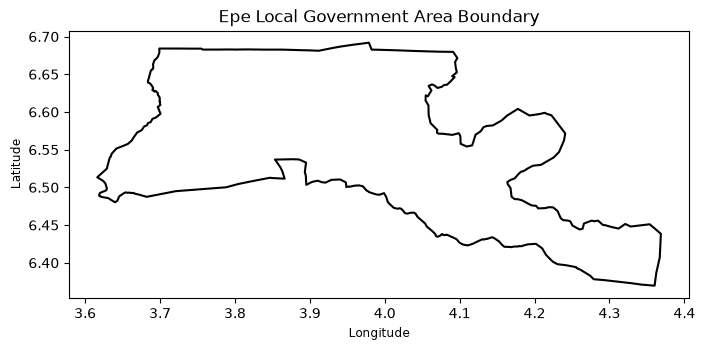

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))

epe_check.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.5
)

ax.set_title("Epe Local Government Area Boundary")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [15]:
print("Coordinate extent of Epe LGA:")

print("Minimum longitude:", epe_check.total_bounds[0])
print("Minimum latitude:", epe_check.total_bounds[1])
print("Maximum longitude:", epe_check.total_bounds[2])
print("Maximum latitude:", epe_check.total_bounds[3])

Coordinate extent of Epe LGA:
Minimum longitude: 3.61619059382087
Minimum latitude: 6.36961033774696
Maximum longitude: 4.3686295177381
Maximum latitude: 6.69193444571812


In [16]:
epe_utm = epe_check.to_crs("EPSG:32631")

print("Original CRS:")
print(epe_check.crs)

print("\nProjected CRS:")
print(epe_utm.crs)

print("\nArea in square metres:")
print(epe_utm.geometry.area.iloc[0])

print("\nArea in square kilometres:")
print(epe_utm.geometry.area.iloc[0] / 1_000_000)

Original CRS:
EPSG:4326

Projected CRS:
EPSG:32631

Area in square metres:
1314234934.1835103

Area in square kilometres:
1314.2349341835104


In [17]:
processed_folder = Path("../data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

projected_file = processed_folder / "epe_lga_boundary_utm31n.gpkg"

epe_utm.to_file(
    projected_file,
    layer="epe_lga_boundary",
    driver="GPKG"
)

print("Projected boundary saved to:")
print(projected_file.resolve())

Projected boundary saved to:
C:\Users\Lioness_eni\data\processed\epe_lga_boundary_utm31n.gpkg


In [18]:
import requests

service_url = (
    "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/"
    "ArcGIS/rest/services/"
    "GRID3_Epe_LGA_GIS/FeatureServer"
)

response = requests.get(
    service_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

service_info = response.json()

print("\nAvailable layers:")

for layer in service_info.get("layers", []):
    print(
        "ID:", layer["id"],
        "| Name:", layer["name"],
        "| Type:", layer["type"]
    )

HTTP status: 200

Available layers:


In [19]:
import requests

service_url = "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/ArcGIS/rest/services/Epe_GIS/FeatureServer"

response = requests.get(
    service_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

service_info = response.json()

print("\nAvailable layers:")

for layer in service_info.get("layers", []):
    print(
        "ID:", layer["id"],
        "| Name:", layer["name"],
        "| Type:", layer["type"],
        "| Geometry:", layer.get("geometryType")
    )

HTTP status: 200

Available layers:


In [20]:
import geopandas as gpd
import requests

base_url = "https://services8.arcgis.com/oTalEaSXAuyNT7xf/ArcGIS/rest/services/DIGITAL_MAPPING_GROUP_6__MAP_OF_EPE_WFL1/FeatureServer"

def get_layer(layer_id):
    url = f"{base_url}/{layer_id}/query"

    params = {
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "f": "geojson"
    }

    response = requests.get(url, params=params, timeout=60)
    print(f"Layer {layer_id} HTTP status:", response.status_code)

    response.raise_for_status()

    data = response.json()

    return gpd.GeoDataFrame.from_features(
        data["features"],
        crs="EPSG:3857"
    )

# Waterways
waterways = get_layer(8)

# Water bodies
waterbodies = get_layer(13)

print("\nWaterways:", len(waterways))
print("Waterbodies:", len(waterbodies))

print("\nWaterways columns:")
print(waterways.columns.tolist())

print("\nWaterbody columns:")
print(waterbodies.columns.tolist())

Layer 8 HTTP status: 200
Layer 13 HTTP status: 200

Waterways: 17
Waterbodies: 18

Waterways columns:
['geometry', 'FID', 'fclass', 'name', 'length', 'Shape__Length']

Waterbody columns:
['geometry', 'FID', 'fclass', 'name', 'area', 'Shape__Area', 'Shape__Length']


In [21]:
print("WATERWAYS")
print(waterways[["FID", "fclass", "name", "length"]].to_string(index=False))

print("\nWATERBODIES")
print(waterbodies[["FID", "fclass", "name", "area"]].to_string(index=False))

WATERWAYS
 FID fclass           name       length
   1  river      Aye River 11431.012338
   2  river     Osun River  3683.418488
   3  river    Oshun River  8108.846903
   4  river    Oshun River  4244.053044
   5  river    Oshun River  1210.494075
   6  river    Oshun River   241.663727
   7  river    Oshun River    54.870169
   8  river        Sunmoge  8956.775771
   9  river Mosafejo River  1876.681276
  10 stream                 8912.123901
  11 stream                  994.691113
  12 stream                 1399.186699
  13 stream                 4646.332096
  14 stream                 8209.609406
  15 stream                 2047.087602
  16 stream                  288.857549
  17  river     Saga River  3268.587581

WATERBODIES
 FID    fclass         name      area
   1     water                    533
   2     water                    351
   3     water                    535
   4     water                    533
   5 riverbank    Omu creek   2723412
   6 riverbank               

In [22]:
waterways_epe = gpd.clip(waterways, epe_check)
waterbodies_epe = gpd.clip(waterbodies, epe_check)

print("Waterways inside Epe LGA:", len(waterways_epe))
print("Waterbodies inside Epe LGA:", len(waterbodies_epe))

C:\Users\Lioness_eni\AppData\Local\Temp\ipykernel_12696\1031218300.py:1: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:3857
Right CRS: EPSG:4326

  waterways_epe = gpd.clip(waterways, epe_check)
C:\Users\Lioness_eni\AppData\Local\Temp\ipykernel_12696\1031218300.py:2: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:3857
Right CRS: EPSG:4326

  waterbodies_epe = gpd.clip(waterbodies, epe_check)


Waterways inside Epe LGA: 17
Waterbodies inside Epe LGA: 18


In [23]:
print("\nNamed waterways:")
print(
    waterways_epe[waterways_epe["name"].notna()][["fclass", "name"]]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nNamed waterbodies:")
print(
    waterbodies_epe[waterbodies_epe["name"].notna()][["fclass", "name"]]
    .drop_duplicates()
    .to_string(index=False)
)


Named waterways:
fclass           name
stream               
 river        Sunmoge
 river Mosafejo River
 river    Oshun River
 river     Saga River
 river     Osun River
 river      Aye River

Named waterbodies:
   fclass         name
    water             
riverbank             
  wetland             
    water Lekki Lagoon
    water   Epe Lagoon
riverbank    Omu creek
    water Lagos Lagoon


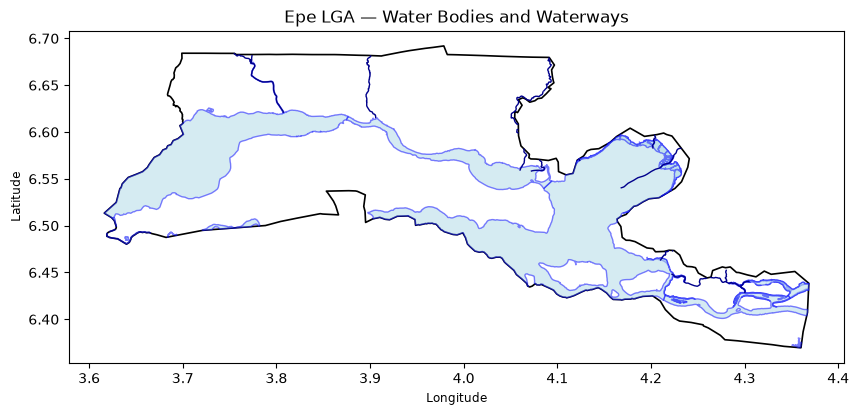

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

epe_check.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)

waterbodies_epe.plot(
    ax=ax,
    color="lightblue",
    edgecolor="blue",
    alpha=0.5
)

waterways_epe.plot(
    ax=ax,
    color="darkblue",
    linewidth=1
)

ax.set_title("Epe LGA — Water Bodies and Waterways")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [25]:
from pathlib import Path

raw_folder = Path("../data/raw")

waterways_file = raw_folder / "epe_waterways.geojson"
waterbodies_file = raw_folder / "epe_waterbodies.geojson"

waterways_epe.to_file(waterways_file, driver="GeoJSON")
waterbodies_epe.to_file(waterbodies_file, driver="GeoJSON")

print("Saved:")
print(waterways_file.resolve())
print(waterbodies_file.resolve())

Saved:
C:\Users\Lioness_eni\data\raw\epe_waterways.geojson
C:\Users\Lioness_eni\data\raw\epe_waterbodies.geojson


In [29]:
import requests

overpass_url = "https://overpass.kumi.systems/api/interpreter"

response = requests.post(
    overpass_url,
    data={"data": query},
    headers={"User-Agent": "Epe-Coastal-Atlas/1.0"},
    timeout=90
)

print("HTTP status:", response.status_code)

response.raise_for_status()

osm_data = response.json()

print("Features found:", len(osm_data["elements"]))

HTTP status: 500


HTTPError: 500 Server Error: Internal Server Error for url: https://overpass.kumi.systems/api/interpreter

In [30]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

data = [
    {
        "name": "Oluwo Modern Fish Market",
        "category": "Fish Market",
        "lat": 6.582271,
        "lon": 3.990089,
        "osm_id": "node/10164480090",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
    {
        "name": "Ebute Oluwo Landing Point",
        "category": "Fish Landing Site",
        "lat": 6.582260,
        "lon": 3.982650,
        "osm_id": "ref_ebute_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Epe Marina Waterfront & Jetty",
        "category": "Fishing Jetty / Harbour",
        "lat": 6.579710,
        "lon": 3.980740,
        "osm_id": "ref_marina_01",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
    {
        "name": "Ebute Erepoto Landing Site",
        "category": "Fish Landing Site",
        "lat": 6.577180,
        "lon": 3.968540,
        "osm_id": "ref_erepoto_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Ebute Berger Landing Site",
        "category": "Fish Landing Site",
        "lat": 6.575986,
        "lon": 3.945330,
        "osm_id": "ref_berger_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Shaldag Aquaculture Farm",
        "category": "Aquaculture Facility",
        "lat": 6.593764,
        "lon": 3.939745,
        "osm_id": "way/10150154736",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
    {
        "name": "Ketu-Ereyun Aquaculture Farm Estate",
        "category": "Aquaculture Facility",
        "lat": 6.583300,
        "lon": 3.983300,
        "osm_id": "ref_ketuereyun_01",
        "evidence_tier": "Tier 2: Secondary / Authoritative Planned",
    },
    {
        "name": "Ebute Afuye Landing Point",
        "category": "Fishing Activity Location",
        "lat": 6.584000,
        "lon": 3.895000,
        "osm_id": "ref_afuye_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Ejinrin Lagoon Waterfront & Jetty",
        "category": "Fishing Jetty / Harbour",
        "lat": 6.602500,
        "lon": 3.874100,
        "osm_id": "ref_ejinrin_01",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
]

df = pd.DataFrame(data)
geometry = [Point(xy) for xy in zip(df["lon"], df["lat"])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

# Reproject to project metric standard UTM Zone 31N
gdf_utm = gdf.to_crs("EPSG:32631")

# Export to GeoPackage
gdf_utm.to_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points",
    driver="GPKG",
)
print(f"Exported {len(gdf_utm)} fisheries features to GPKG.")

Exported 9 fisheries features to GPKG.


In [31]:
import geopandas as gpd

# Load Epe boundary
epe = gpd.read_file(
    "data/processed/epe_lga_boundary_utm31n.gpkg",
    layer="epe_lga_boundary"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Check CRS
print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

# Check which points fall inside Epe LGA
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

# Show the results
print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/processed/epe_lga_boundary_utm31n.gpkg: No such file or directory

In [32]:
from pathlib import Path

print("Current folder:")
print(Path.cwd())

print("\nProcessed folder contents:")
for item in Path("../data/processed").iterdir():
    print(item)

Current folder:
C:\Users\Lioness_eni\Epe_Coastal_Atlas

Processed folder contents:
..\data\processed\epe_lga_boundary_utm31n.gpkg


In [33]:
import geopandas as gpd

# Load Epe boundary
epe = gpd.read_file(
    "data/processed/epe_lga_boundary_utm31n.gpkg",
    layer="epe_lga_boundary"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Check CRS
print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

# Check which points fall inside Epe
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/processed/epe_lga_boundary_utm31n.gpkg: No such file or directory

In [34]:
from pathlib import Path

print("Current folder:")
print(Path.cwd())

print("\nProcessed folder contents:")
for item in Path("../data/processed").iterdir():
    print(item)

Current folder:
C:\Users\Lioness_eni\Epe_Coastal_Atlas

Processed folder contents:
..\data\processed\epe_lga_boundary_utm31n.gpkg


In [35]:
import geopandas as gpd

# Load Epe boundary
epe = gpd.read_file(
    "data/processed/epe_lga_boundary_utm31n.gpkg",
    layer="epe_lga_boundary"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Check CRS
print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

# Check which points fall inside Epe
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/processed/epe_lga_boundary_utm31n.gpkg: No such file or directory

In [36]:
import geopandas as gpd

# Load Epe boundary from the raw GeoJSON
epe = gpd.read_file(
    "data/raw/epe_lga_boundary.geojson"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Put boundary into the same CRS
epe = epe.to_crs("EPSG:32631")

# Check which points fall inside Epe
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/raw/epe_lga_boundary.geojson: No such file or directory

In [37]:
# Recreate the fisheries points from the data already collected

import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, box

# Fisheries dataset
data = [
    {"name": "Oluwo Modern Fish Market", "category": "Fish Market", "lat": 6.582271, "lon": 3.990089},
    {"name": "Ebute Oluwo Landing Point", "category": "Fish Landing Site", "lat": 6.582260, "lon": 3.982650},
    {"name": "Epe Marina Waterfront & Jetty", "category": "Fishing Jetty / Harbour", "lat": 6.579710, "lon": 3.980740},
    {"name": "Ebute Erepoto Landing Site", "category": "Fish Landing Site", "lat": 6.577180, "lon": 3.968540},
    {"name": "Ebute Berger Landing Site", "category": "Fish Landing Site", "lat": 6.575986, "lon": 3.945330},
    {"name": "Shaldag Aquaculture Farm", "category": "Aquaculture Facility", "lat": 6.593764, "lon": 3.939745},
    {"name": "Ketu-Ereyun Aquaculture Farm Estate", "category": "Aquaculture Facility", "lat": 6.583300, "lon": 3.983300},
    {"name": "Ebute Afuye Landing Point", "category": "Fishing Activity Location", "lat": 6.584000, "lon": 3.895000},
    {"name": "Ejinrin Lagoon Waterfront & Jetty", "category": "Fishing Jetty / Harbour", "lat": 6.602500, "lon": 3.874100},
]

df = pd.DataFrame(data)

geometry = [
    Point(lon, lat)
    for lon, lat in zip(df["lon"], df["lat"])
]

fisheries = gpd.GeoDataFrame(
    df,
    geometry=geometry,
    crs="EPSG:4326"
)

# Epe LGA bounding box from our verified boundary dataset
epe_bbox = box(
    3.61619059382087,   # minimum longitude
    6.36961033774696,   # minimum latitude
    4.3686295177381,    # maximum longitude
    6.69193444571812    # maximum latitude
)

# Preliminary geographic check
fisheries["within_epe_bbox"] = fisheries.geometry.within(epe_bbox)

print("Total fisheries/aquaculture features:", len(fisheries))
print("Within Epe boundary extent:", fisheries["within_epe_bbox"].sum())
print("Outside Epe boundary extent:", (~fisheries["within_epe_bbox"]).sum())

print(
    fisheries[
        ["name", "category", "lat", "lon", "within_epe_bbox"]
    ].to_string(index=False)
)

Total fisheries/aquaculture features: 9
Within Epe boundary extent: 9
Outside Epe boundary extent: 0
                               name                  category      lat      lon  within_epe_bbox
           Oluwo Modern Fish Market               Fish Market 6.582271 3.990089             True
          Ebute Oluwo Landing Point         Fish Landing Site 6.582260 3.982650             True
      Epe Marina Waterfront & Jetty   Fishing Jetty / Harbour 6.579710 3.980740             True
         Ebute Erepoto Landing Site         Fish Landing Site 6.577180 3.968540             True
          Ebute Berger Landing Site         Fish Landing Site 6.575986 3.945330             True
           Shaldag Aquaculture Farm      Aquaculture Facility 6.593764 3.939745             True
Ketu-Ereyun Aquaculture Farm Estate      Aquaculture Facility 6.583300 3.983300             True
          Ebute Afuye Landing Point Fishing Activity Location 6.584000 3.895000             True
  Ejinrin Lagoon Waterfron

In [38]:
# Add evidence/source information
fisheries["evidence_tier"] = "Tier 2: Secondary / Mapped or Field Survey"
fisheries["source"] = "OpenStreetMap / Secondary Reference"
fisheries["access_date"] = "2026-10-08"

# Reproject to project CRS
fisheries_utm = fisheries.to_crs("EPSG:32631")

# Create output folder if needed
from pathlib import Path
Path("data/processed").mkdir(parents=True, exist_ok=True)

# Save GeoPackage
output_file = "data/processed/epe_fisheries_aquaculture_utm31n.gpkg"

fisheries_utm.to_file(
    output_file,
    layer="fisheries_aquaculture_points",
    driver="GPKG"
)

print(f"Saved {len(fisheries_utm)} features.")
print(f"File: {output_file}")
print(f"CRS: {fisheries_utm.crs}")

Saved 9 features.
File: data/processed/epe_fisheries_aquaculture_utm31n.gpkg
CRS: EPSG:32631


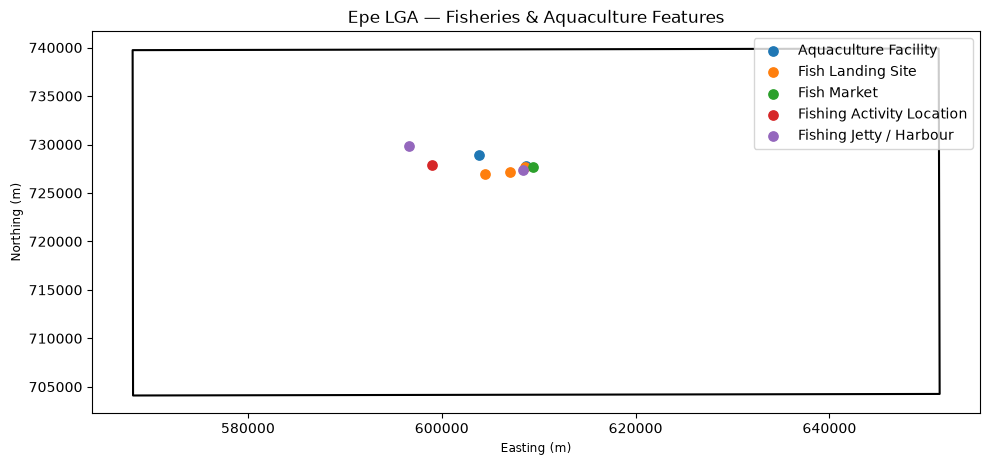

In [39]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

# Epe boundary
epe_utm = epe_bbox

# Convert bbox to GeoDataFrame in UTM
epe_boundary = gpd.GeoDataFrame(
    {"name": ["Epe LGA"]},
    geometry=[epe_utm],
    crs="EPSG:4326"
).to_crs("EPSG:32631")

# Plot boundary
epe_boundary.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.5
)

# Plot fisheries/aquaculture
fisheries_utm.plot(
    ax=ax,
    markersize=45,
    column="category",
    legend=True
)

ax.set_title("Epe LGA — Fisheries & Aquaculture Features")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

In [5]:

# CELL 4: INVENTORY SUMMARY AND GEOMETRY READINESS

# 1. Confirm that the inventory exists
print("Total records:", len(fisheries_candidates_df))

# 2. Create the geometry_ready column
# This identifies records with existing coordinates.
# Approximate coordinates are included but are NOT verified.
fisheries_candidates_df["geometry_ready"] = (
    fisheries_candidates_df["coordinate_status"].isin(
        ["Existing coordinate", "Existing approximate coordinate"]
    )
)

# 3. Count records with and without coordinates
print(
    "Geometry-ready:",
    int(fisheries_candidates_df["geometry_ready"].sum())
)

print(
    "Coordinates still needed:",
    int((~fisheries_candidates_df["geometry_ready"]).sum())
)

# 4. Display each record and its readiness status
display(
    fisheries_candidates_df[
        ["name", "coordinate_status", "geometry_ready"]
    ]
)


Total records: 12
Geometry-ready: 10
Coordinates still needed: 2


,name,coordinate_status,geometry_ready
0,Oluwo Fish Market,Existing coordinate,True
1,Chief Market Fish Landing Station,Needs verification,False
2,Epe Fish Collecting Center,Needs verification,False
3,Ejinrin Fisheries / Waterfront Area,Existing coordinate,True
4,Ebute Oluwo Landing Point,Existing coordinate,True
5,Ebute Erepoto Landing Site,Existing coordinate,True
6,Ebute Berger Landing Site,Existing coordinate,True
7,Ebute Afuye Landing Point,Existing coordinate,True
8,Epe Marina Waterfront & Jetty,Existing coordinate,True
9,Ejinrin Lagoon Waterfront & Jetty,Existing coordinate,True


In [41]:
print("Total candidate fisheries/aquaculture records:",
      len(fisheries_candidates_df))

print("\nBy category:")
print(fisheries_candidates_df["category"].value_counts())

print("\nBy evidence tier:")
print(fisheries_candidates_df["evidence_tier"].value_counts())

Total candidate fisheries/aquaculture records: 12

By category:
category
Fish Landing Site                   4
Fishing Activity Location           2
Fishing Jetty / Harbour             2
Aquaculture Facility                2
Fish Market                         1
Fish Landing / Collection Center    1
Name: count, dtype: int64

By evidence tier:
evidence_tier
Tier 2: Secondary / Mapped            4
Tier 2: Field / Secondary             4
Tier 1: Documented / Authoritative    1
Tier 1: Published Research            1
Tier 2: Historical / Secondary        1
Tier 2: Planned / Secondary           1
Name: count, dtype: int64


In [42]:
# Add verification status based on evidence and coordinate availability

def verification_status(row):
    if row["coordinate_status"] == "Existing coordinate":
        if row["evidence_tier"].startswith("Tier 1"):
            return "Documented + coordinate available"
        else:
            return "Mapped/secondary + coordinate available"
    elif row["coordinate_status"] == "Existing approximate coordinate":
        return "Approximate location — verify before analysis"
    else:
        return "Documented location — coordinate needed"

fisheries_candidates_df["verification_status"] = (
    fisheries_candidates_df.apply(verification_status, axis=1)
)

# Add a geometry-ready flag
fisheries_candidates_df["geometry_ready"] = (
    fisheries_candidates_df["coordinate_status"]
    .isin(["Existing coordinate"])
)

# Display the important fields
fisheries_candidates_df[
    [
        "name",
        "category",
        "evidence_tier",
        "coordinate_status",
        "verification_status",
        "geometry_ready"
    ]
]

,name,category,evidence_tier,coordinate_status,verification_status,geometry_ready
0,Oluwo Fish Market,Fish Market,Tier 1: Documented / Authoritative,Existing coordinate,Documented + coordinate available,True
1,Chief Market Fish Landing Station,Fish Landing Site,Tier 1: Published Research,Needs verification,Documented location — coordinate needed,False
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Tier 2: Historical / Secondary,Needs verification,Documented location — coordinate needed,False
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Tier 2: Secondary / Mapped,Existing coordinate,Mapped/secondary + coordinate available,True
4,Ebute Oluwo Landing Point,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
5,Ebute Erepoto Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
6,Ebute Berger Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
7,Ebute Afuye Landing Point,Fishing Activity Location,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
8,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing coordinate,Mapped/secondary + coordinate available,True
9,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing coordinate,Mapped/secondary + coordinate available,True


In [43]:
# Save the candidate inventory as CSV

fisheries_candidates_df.to_csv(
    "data/processed/epe_fisheries_aquaculture_candidate_inventory.csv",
    index=False
)

print("Saved:")
print("data/processed/epe_fisheries_aquaculture_candidate_inventory.csv")

Saved:
data/processed/epe_fisheries_aquaculture_candidate_inventory.csv


In [6]:

# CELL 5: INSPECT COORDINATE FIELDS

print("Column names:")
print(fisheries_candidates_df.columns.tolist())

print("\nCoordinate-related columns:")
coordinate_columns = [
    col for col in fisheries_candidates_df.columns
    if any(word in col.lower() for word in ["lat", "lon", "long", "coord", "geometry"])
]
print(coordinate_columns)

print("\nInventory preview:")
display(fisheries_candidates_df.head(12))


Column names:
['name', 'category', 'evidence_tier', 'source', 'coordinate_status', 'notes', 'geometry_ready']

Coordinate-related columns:
['coordinate_status', 'geometry_ready']

Inventory preview:


,name,category,evidence_tier,source,coordinate_status,notes,geometry_ready
0,Oluwo Fish Market,Fish Market,Tier 1: Documented / Authoritative,Lagos State Government; PUNCH; Nigerian Tribune,Existing coordinate,Major fish trading location on the lagoon wate...,True
1,Chief Market Fish Landing Station,Fish Landing Site,Tier 1: Published Research,Scientific literature on fish fauna of Epe Lagoon,Needs verification,Documented landing station used by local fishe...,False
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Tier 2: Historical / Secondary,FAO fisheries documentation,Needs verification,Historical fish collection/distribution center.,False
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Tier 2: Secondary / Mapped,Epe planning map and existing spatial inventory,Existing coordinate,Waterfront area associated with fishing and bo...,True
4,Ebute Oluwo Landing Point,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
5,Ebute Erepoto Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
6,Ebute Berger Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
7,Ebute Afuye Landing Point,Fishing Activity Location,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
8,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing project inventory,Existing coordinate,Relevant for fisheries access and waterfront a...,True
9,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing project inventory,Existing coordinate,Relevant for fisheries access and waterfront a...,True


In [44]:
# Quick verification summary

print("Total records:", len(fisheries_candidates_df))
print(
    "Geometry-ready:",
    fisheries_candidates_df["geometry_ready"].sum()
)
print(
    "Coordinates still needed:",
    (~fisheries_candidates_df["geometry_ready"]).sum()
)
print(
    "\nVerification status:"
)
print(
    fisheries_candidates_df["verification_status"].value_counts()
)

Total records: 12
Geometry-ready: 9
Coordinates still needed: 3

Verification status:
verification_status
Mapped/secondary + coordinate available          8
Documented location — coordinate needed          2
Documented + coordinate available                1
Approximate location — verify before analysis    1
Name: count, dtype: int64


In [4]:

# Inspect the inventory and calculate geometry readiness

print("Total records:", len(fisheries_candidates_df))

# Check which coordinate columns are available
print("\nCoordinate-related columns:")
print([
    col for col in fisheries_candidates_df.columns
    if any(word in col.lower() for word in ["lat", "lon", "coord", "geometry"])
])

# Calculate geometry readiness from coordinate status
fisheries_candidates_df["geometry_ready"] = (
    fisheries_candidates_df["coordinate_status"]
    .isin(["Existing coordinate", "Existing approximate coordinate"])
)

print("\nGeometry-ready:", fisheries_candidates_df["geometry_ready"].sum())
print(
    "Coordinates still needed:",
    (~fisheries_candidates_df["geometry_ready"]).sum()
)

print("\nVerification status:")
display(
    fisheries_candidates_df[
        ["name", "coordinate_status", "geometry_ready"]
    ]
)


Total records: 12


KeyError: 'geometry_ready'

In [7]:

# DIAGNOSTIC CELL: CHECK THE CURRENT DATAFRAME

print("DataFrame exists:", "fisheries_candidates_df" in globals())

if "fisheries_candidates_df" in globals():
    print("Columns:", fisheries_candidates_df.columns.tolist())
    print("Record count:", len(fisheries_candidates_df))

    if "coordinate_status" in fisheries_candidates_df.columns:
        fisheries_candidates_df["geometry_ready"] = (
            fisheries_candidates_df["coordinate_status"].isin(
                ["Existing coordinate", "Existing approximate coordinate"]
            )
        )
        print("Geometry-ready:", int(fisheries_candidates_df["geometry_ready"].sum()))
        print(
            "Coordinates still needed:",
            int((~fisheries_candidates_df["geometry_ready"]).sum())
        )
    else:
        print("The coordinate_status column is missing.")
else:
    print("The inventory DataFrame has not been created in this kernel.")


DataFrame exists: True
Columns: ['name', 'category', 'evidence_tier', 'source', 'coordinate_status', 'notes', 'geometry_ready']
Record count: 12
Geometry-ready: 10
Coordinates still needed: 2


In [8]:

# CELL 6: CHECK FOR LATITUDE AND LONGITUDE

print("All available columns:")
for column in fisheries_candidates_df.columns:
    print("-", column)

# Look for possible coordinate fields
possible_coordinate_columns = [
    column for column in fisheries_candidates_df.columns
    if any(term in column.lower() for term in
           ["latitude", "longitude", "lat", "lon", "long", "x", "y"])
]

print("\nPossible coordinate columns:")
print(possible_coordinate_columns)

# Display the inventory fields needed for the next step
display(fisheries_candidates_df.head(12))



All available columns:
- name
- category
- evidence_tier
- source
- coordinate_status
- notes
- geometry_ready

Possible coordinate columns:
['category', 'geometry_ready']


,name,category,evidence_tier,source,coordinate_status,notes,geometry_ready
0,Oluwo Fish Market,Fish Market,Tier 1: Documented / Authoritative,Lagos State Government; PUNCH; Nigerian Tribune,Existing coordinate,Major fish trading location on the lagoon wate...,True
1,Chief Market Fish Landing Station,Fish Landing Site,Tier 1: Published Research,Scientific literature on fish fauna of Epe Lagoon,Needs verification,Documented landing station used by local fishe...,False
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Tier 2: Historical / Secondary,FAO fisheries documentation,Needs verification,Historical fish collection/distribution center.,False
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Tier 2: Secondary / Mapped,Epe planning map and existing spatial inventory,Existing coordinate,Waterfront area associated with fishing and bo...,True
4,Ebute Oluwo Landing Point,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
5,Ebute Erepoto Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
6,Ebute Berger Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
7,Ebute Afuye Landing Point,Fishing Activity Location,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.,True
8,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing project inventory,Existing coordinate,Relevant for fisheries access and waterfront a...,True
9,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing project inventory,Existing coordinate,Relevant for fisheries access and waterfront a...,True


In [9]:

# CELL 7: FIND EXISTING COORDINATE DATA

# A. Find DataFrames already loaded in notebook memory
print("DataFrames currently in memory:")

for variable_name, variable_value in list(globals().items()):
    if isinstance(variable_value, __import__("pandas").DataFrame):
        print(
            f"\nVariable: {variable_name}"
            f"\nShape: {variable_value.shape}"
            f"\nColumns: {variable_value.columns.tolist()}"
        )

# B. Check the current working directory
from pathlib import Path

print("\nCurrent notebook directory:")
print(Path.cwd())

# C. Search nearby project folders for GeoPackage files
print("\nGeoPackage files found nearby:")

for file_path in Path.cwd().parent.rglob("*.gpkg"):
    print(file_path)


DataFrames currently in memory:

Variable: _
Shape: (12, 7)
Columns: ['name', 'category', 'evidence_tier', 'source', 'coordinate_status', 'notes', 'geometry_ready']

Variable: fisheries_candidates_df
Shape: (12, 7)
Columns: ['name', 'category', 'evidence_tier', 'source', 'coordinate_status', 'notes', 'geometry_ready']

Variable: _3
Shape: (12, 7)
Columns: ['name', 'category', 'evidence_tier', 'source', 'coordinate_status', 'notes', 'geometry_ready']

Current notebook directory:
C:\Users\Lioness_eni\GitHub\epe-coastal-atlas

GeoPackage files found nearby:
C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\data\processed\epe_fisheries_aquaculture_utm31n.gpkg


In [11]:

# CELL 8A: INSPECT THE GEOPACKAGE USING GEOPANDAS

from pathlib import Path
import geopandas as gpd

# Locate the existing GeoPackage
gpkg_path = (
    Path.cwd()
    / "data"
    / "processed"
    / "epe_fisheries_aquaculture_utm31n.gpkg"
)

print("File exists:", gpkg_path.exists())
print("File path:", gpkg_path)

if gpkg_path.exists():
    try:
        # Read the first spatial layer
        spatial_data = gpd.read_file(gpkg_path)

        print("\nNumber of features:", len(spatial_data))
        print("CRS:", spatial_data.crs)
        print("\nGeometry types:")
        print(spatial_data.geometry.geom_type.value_counts())
        print("\nColumns:")
        print(spatial_data.columns.tolist())

        display(spatial_data.head())

    except Exception as error:
        print("Could not read the GeoPackage.")
        print("Error type:", type(error).__name__)
        print("Error details:", error)
else:
    print("Check the project folder and file path.")


File exists: True
File path: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\data\processed\epe_fisheries_aquaculture_utm31n.gpkg

Number of features: 9
CRS: EPSG:32631

Geometry types:
Point    9
Name: count, dtype: int64

Columns:
['name', 'category', 'lat', 'lon', 'within_epe_bbox', 'evidence_tier', 'source', 'access_date', 'geometry']


,name,category,lat,lon,within_epe_bbox,evidence_tier,source,access_date,geometry
0,Oluwo Modern Fish Market,Fish Market,6.582271,3.990089,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (609456.048 727679.19)
1,Ebute Oluwo Landing Point,Fish Landing Site,6.582260,3.982650,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (608633.576 727676.35)
2,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,6.579710,3.980740,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (608422.956 727394.006)
3,Ebute Erepoto Landing Site,Fish Landing Site,6.577180,3.968540,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (607074.634 727111.66)
4,Ebute Berger Landing Site,Fish Landing Site,6.575986,3.945330,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (604508.726 726974.742)


In [12]:

# CELL 9: QUALITY CHECK OF THE FISHERIES SPATIAL DATA

print("Total spatial records:", len(spatial_data))

print("\nCoordinate Reference System:")
print(spatial_data.crs)

print("\nGeometry types:")
print(spatial_data.geometry.geom_type.value_counts())

print("\nMissing geometries:")
print(spatial_data.geometry.isna().sum())

print("\nEmpty geometries:")
print(spatial_data.geometry.is_empty.sum())

print("\nInvalid geometries:")
print((~spatial_data.geometry.is_valid).sum())

# Check whether the expected coordinate and status fields exist
required_columns = ["name", "lat", "lon", "within_epe_bbox"]
missing_columns = [
    col for col in required_columns
    if col not in spatial_data.columns
]

print("\nMissing expected columns:", missing_columns)

if "within_epe_bbox" in spatial_data.columns:
    print("\nWithin Epe bounding box:")
    print(spatial_data["within_epe_bbox"].value_counts(dropna=False))

# Show the complete inventory for inspection
display(spatial_data)


Total spatial records: 9

Coordinate Reference System:
EPSG:32631

Geometry types:
Point    9
Name: count, dtype: int64

Missing geometries:
0

Empty geometries:
0

Invalid geometries:
0

Missing expected columns: []

Within Epe bounding box:
within_epe_bbox
True    9
Name: count, dtype: int64


,name,category,lat,lon,within_epe_bbox,evidence_tier,source,access_date,geometry
0,Oluwo Modern Fish Market,Fish Market,6.582271,3.990089,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (609456.048 727679.19)
1,Ebute Oluwo Landing Point,Fish Landing Site,6.582260,3.982650,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (608633.576 727676.35)
2,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,6.579710,3.980740,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (608422.956 727394.006)
3,Ebute Erepoto Landing Site,Fish Landing Site,6.577180,3.968540,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (607074.634 727111.66)
4,Ebute Berger Landing Site,Fish Landing Site,6.575986,3.945330,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (604508.726 726974.742)
5,Shaldag Aquaculture Farm,Aquaculture Facility,6.593764,3.939745,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (603887.538 728939.101)
6,Ketu-Ereyun Aquaculture Farm Estate,Aquaculture Facility,6.583300,3.983300,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (608705.216 727791.475)
7,Ebute Afuye Landing Point,Fishing Activity Location,6.584000,3.895000,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (598942.569 727850.518)
8,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,6.602500,3.874100,True,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,2026-10-08,POINT (596628.306 729891.737)


In [13]:

# CELL 10: COMPARE EVIDENCE INVENTORY WITH SPATIAL DATA

# Standardise names for comparison without changing the original records
evidence_names = set(
    fisheries_candidates_df["name"]
    .dropna()
    .str.strip()
    .str.casefold()
)

spatial_names = set(
    spatial_data["name"]
    .dropna()
    .str.strip()
    .str.casefold()
)

# Locations appearing in both datasets
matched_names = evidence_names & spatial_names

# Locations documented in the evidence inventory but not mapped
not_yet_mapped = evidence_names - spatial_names

# Spatial records that do not match the evidence inventory by name
spatial_only = spatial_names - evidence_names

print("Evidence inventory records:", len(fisheries_candidates_df))
print("Spatial features:", len(spatial_data))
print("Matching names:", len(matched_names))
print("Evidence records not matched to spatial data:", len(not_yet_mapped))
print("Spatial names not matched to evidence inventory:", len(spatial_only))

print("\nEvidence records not matched to spatial data:")
display(
    fisheries_candidates_df[
        fisheries_candidates_df["name"].str.strip().str.casefold().isin(
            not_yet_mapped
        )
    ][["name", "category", "coordinate_status", "evidence_tier"]]
)

print("\nSpatial records not matched to evidence inventory:")
display(
    spatial_data[
        spatial_data["name"].str.strip().str.casefold().isin(spatial_only)
    ][["name", "category", "lat", "lon"]]
)


Evidence inventory records: 12
Spatial features: 9
Matching names: 8
Evidence records not matched to spatial data: 4
Spatial names not matched to evidence inventory: 1

Evidence records not matched to spatial data:


,name,category,coordinate_status,evidence_tier
0,Oluwo Fish Market,Fish Market,Existing coordinate,Tier 1: Documented / Authoritative
1,Chief Market Fish Landing Station,Fish Landing Site,Needs verification,Tier 1: Published Research
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Needs verification,Tier 2: Historical / Secondary
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Existing coordinate,Tier 2: Secondary / Mapped



Spatial records not matched to evidence inventory:


,name,category,lat,lon
0,Oluwo Modern Fish Market,Fish Market,6.582271,3.990089


In [15]:

# CELL 11: PRINT COMPLETE RECONCILIATION RESULTS

evidence_names = set(
    fisheries_candidates_df["name"].dropna().str.strip().str.casefold()
)

spatial_names = set(
    spatial_data["name"].dropna().str.strip().str.casefold()
)

matched = evidence_names & spatial_names
unmatched_evidence = evidence_names - spatial_names
unmatched_spatial = spatial_names - evidence_names

print(f"Evidence inventory: {len(fisheries_candidates_df)} records")
print(f"Spatial dataset: {len(spatial_data)} features")
print(f"Matched names: {len(matched)}")
print(f"Unmatched evidence names: {len(unmatched_evidence)}")
print(f"Unmatched spatial names: {len(unmatched_spatial)}")

print("\nALL UNMATCHED EVIDENCE RECORDS:")
for name in sorted(unmatched_evidence):
    print("-", name)

print("\nALL UNMATCHED SPATIAL RECORDS:")
for name in sorted(unmatched_spatial):
    print("-", name)

print("\nALL MATCHED NAMES:")
for name in sorted(matched):
    print("-", name)


Evidence inventory: 12 records
Spatial dataset: 9 features
Matched names: 8
Unmatched evidence names: 4
Unmatched spatial names: 1

ALL UNMATCHED EVIDENCE RECORDS:
- chief market fish landing station
- ejinrin fisheries / waterfront area
- epe fish collecting center
- oluwo fish market

ALL UNMATCHED SPATIAL RECORDS:
- oluwo modern fish market

ALL MATCHED NAMES:
- ebute afuye landing point
- ebute berger landing site
- ebute erepoto landing site
- ebute oluwo landing point
- ejinrin lagoon waterfront & jetty
- epe marina waterfront & jetty
- ketu-ereyun aquaculture farm estate
- shaldag aquaculture farm


In [16]:

# CELL 13: CREATE A RECONCILIATION TABLE

reconciliation_df = fisheries_candidates_df.copy()

# Standardise names for comparison only
reconciliation_df["_comparison_name"] = (
    reconciliation_df["name"].str.strip().str.casefold()
)

spatial_name_set = set(
    spatial_data["name"].dropna().str.strip().str.casefold()
)

# Assign a reconciliation status
reconciliation_df["reconciliation_status"] = (
    reconciliation_df["_comparison_name"]
    .isin(spatial_name_set)
    .map({
        True: "Exact name match",
        False: "Investigate name or spatial record"
    })
)

# Display the working table
display(
    reconciliation_df[
        [
            "name",
            "category",
            "coordinate_status",
            "evidence_tier",
            "reconciliation_status"
        ]
    ]
)

print("\nReconciliation summary:")
print(reconciliation_df["reconciliation_status"].value_counts())

# Remove the temporary comparison column
reconciliation_df.drop(
    columns=["_comparison_name"],
    inplace=True
)


,name,category,coordinate_status,evidence_tier,reconciliation_status
0,Oluwo Fish Market,Fish Market,Existing coordinate,Tier 1: Documented / Authoritative,Investigate name or spatial record
1,Chief Market Fish Landing Station,Fish Landing Site,Needs verification,Tier 1: Published Research,Investigate name or spatial record
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Needs verification,Tier 2: Historical / Secondary,Investigate name or spatial record
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Existing coordinate,Tier 2: Secondary / Mapped,Investigate name or spatial record
4,Ebute Oluwo Landing Point,Fish Landing Site,Existing coordinate,Tier 2: Field / Secondary,Exact name match
5,Ebute Erepoto Landing Site,Fish Landing Site,Existing coordinate,Tier 2: Field / Secondary,Exact name match
6,Ebute Berger Landing Site,Fish Landing Site,Existing coordinate,Tier 2: Field / Secondary,Exact name match
7,Ebute Afuye Landing Point,Fishing Activity Location,Existing coordinate,Tier 2: Field / Secondary,Exact name match
8,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,Existing coordinate,Tier 2: Secondary / Mapped,Exact name match
9,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,Existing coordinate,Tier 2: Secondary / Mapped,Exact name match



Reconciliation summary:
reconciliation_status
Exact name match                      8
Investigate name or spatial record    4
Name: count, dtype: int64


In [17]:

# CELL 14: RECONCILE THE CHIEF MARKET / AFUYE ALIAS

# Record the locally confirmed alternative-name relationship
name_aliases = {
    "chief market fish landing station": "ebute afuye landing point"
}

# Standardise the spatial names
spatial_name_set = set(
    spatial_data["name"].dropna().str.strip().str.casefold()
)

# Copy the evidence inventory for reconciliation
reconciliation_df = fisheries_candidates_df.copy()

reconciliation_df["_comparison_name"] = (
    reconciliation_df["name"].str.strip().str.casefold()
)

# Apply the alias rule only for matching purposes
reconciliation_df["_match_name"] = (
    reconciliation_df["_comparison_name"]
    .replace(name_aliases)
)

reconciliation_df["reconciliation_status"] = (
    reconciliation_df["_match_name"]
    .isin(spatial_name_set)
    .map({
        True: "Matched by name or confirmed alias",
        False: "Investigate name or spatial record"
    })
)

display(
    reconciliation_df[
        [
            "name",
            "coordinate_status",
            "reconciliation_status"
        ]
    ]
)

print("\nUpdated reconciliation summary:")
print(reconciliation_df["reconciliation_status"].value_counts())


,name,coordinate_status,reconciliation_status
0,Oluwo Fish Market,Existing coordinate,Investigate name or spatial record
1,Chief Market Fish Landing Station,Needs verification,Matched by name or confirmed alias
2,Epe Fish Collecting Center,Needs verification,Investigate name or spatial record
3,Ejinrin Fisheries / Waterfront Area,Existing coordinate,Investigate name or spatial record
4,Ebute Oluwo Landing Point,Existing coordinate,Matched by name or confirmed alias
5,Ebute Erepoto Landing Site,Existing coordinate,Matched by name or confirmed alias
6,Ebute Berger Landing Site,Existing coordinate,Matched by name or confirmed alias
7,Ebute Afuye Landing Point,Existing coordinate,Matched by name or confirmed alias
8,Epe Marina Waterfront & Jetty,Existing coordinate,Matched by name or confirmed alias
9,Ejinrin Lagoon Waterfront & Jetty,Existing coordinate,Matched by name or confirmed alias



Updated reconciliation summary:
reconciliation_status
Matched by name or confirmed alias    9
Investigate name or spatial record    3
Name: count, dtype: int64


In [18]:

# CELL 15: REVIEW THE THREE UNRESOLVED RECORDS

unresolved_df = reconciliation_df[
    reconciliation_df["reconciliation_status"]
    == "Investigate name or spatial record"
].copy()

display(
    unresolved_df[
        [
            "name",
            "category",
            "evidence_tier",
            "source",
            "coordinate_status",
            "notes"
        ]
    ]
)


,name,category,evidence_tier,source,coordinate_status,notes
0,Oluwo Fish Market,Fish Market,Tier 1: Documented / Authoritative,Lagos State Government; PUNCH; Nigerian Tribune,Existing coordinate,Major fish trading location on the lagoon wate...
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Tier 2: Historical / Secondary,FAO fisheries documentation,Needs verification,Historical fish collection/distribution center.
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Tier 2: Secondary / Mapped,Epe planning map and existing spatial inventory,Existing coordinate,Waterfront area associated with fishing and bo...


In [19]:

# CELL 17: APPLY CONFIRMED LOCATION ALIASES

# Confirmed alternative names mapped to canonical spatial names
name_aliases = {
    "chief market fish landing station": "ebute afuye landing point",
    "oluwo fish market": "oluwo modern fish market",
}

# Standardise spatial names for comparison
spatial_name_set = set(
    spatial_data["name"]
    .dropna()
    .str.strip()
    .str.casefold()
)

# Copy the original evidence inventory
reconciliation_df = fisheries_candidates_df.copy()

# Normalise names for matching only
reconciliation_df["_comparison_name"] = (
    reconciliation_df["name"]
    .str.strip()
    .str.casefold()
)

# Apply confirmed aliases
reconciliation_df["_match_name"] = (
    reconciliation_df["_comparison_name"]
    .replace(name_aliases)
)

# Classify each record
reconciliation_df["reconciliation_status"] = (
    reconciliation_df["_match_name"]
    .isin(spatial_name_set)
    .map({
        True: "Matched by name or confirmed alias",
        False: "Parked for later investigation"
    })
)

# Show the summary and the individual records
print("Reconciliation summary:")
print(reconciliation_df["reconciliation_status"].value_counts())

print("\nRecords parked for later:")
display(
    reconciliation_df.loc[
        reconciliation_df["reconciliation_status"]
        == "Parked for later investigation",
        ["name", "category", "coordinate_status", "evidence_tier"]
    ]
)


Reconciliation summary:
reconciliation_status
Matched by name or confirmed alias    10
Parked for later investigation         2
Name: count, dtype: int64

Records parked for later:


,name,category,coordinate_status,evidence_tier
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Needs verification,Tier 2: Historical / Secondary
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Existing coordinate,Tier 2: Secondary / Mapped


In [20]:

# CELL 18: BUILD THE CANONICAL FISHERIES INVENTORY

# 1. Keep records matched to existing spatial features.
matched_inventory = reconciliation_df.loc[
    reconciliation_df["reconciliation_status"]
    == "Matched by name or confirmed alias"
].copy()

# 2. Keep unresolved records in a separate review table.
parked_inventory = reconciliation_df.loc[
    reconciliation_df["reconciliation_status"]
    == "Parked for later investigation"
].copy()

# 3. Standardise the two confirmed aliases in the matched inventory.
canonical_names = {
    "chief market fish landing station": "Ebute Afuye Landing Point",
    "oluwo fish market": "Oluwo Modern Fish Market",
}

matched_inventory["canonical_name"] = (
    matched_inventory["_comparison_name"]
    .map(canonical_names)
    .fillna(matched_inventory["name"])
)

# 4. Display the results for review.
print("Matched inventory:", len(matched_inventory), "records")
print("Parked for later:", len(parked_inventory), "records")

print("\nCanonical inventory:")
display(
    matched_inventory[
        ["name", "canonical_name", "category",
         "evidence_tier", "coordinate_status"]
    ]
)

print("\nRecords reserved for later investigation:")
display(
    parked_inventory[
        ["name", "category", "evidence_tier",
         "coordinate_status", "notes"]
    ]
)


Matched inventory: 10 records
Parked for later: 2 records

Canonical inventory:


,name,canonical_name,category,evidence_tier,coordinate_status
0,Oluwo Fish Market,Oluwo Modern Fish Market,Fish Market,Tier 1: Documented / Authoritative,Existing coordinate
1,Chief Market Fish Landing Station,Ebute Afuye Landing Point,Fish Landing Site,Tier 1: Published Research,Needs verification
4,Ebute Oluwo Landing Point,Ebute Oluwo Landing Point,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate
5,Ebute Erepoto Landing Site,Ebute Erepoto Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate
6,Ebute Berger Landing Site,Ebute Berger Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate
7,Ebute Afuye Landing Point,Ebute Afuye Landing Point,Fishing Activity Location,Tier 2: Field / Secondary,Existing coordinate
8,Epe Marina Waterfront & Jetty,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing coordinate
9,Ejinrin Lagoon Waterfront & Jetty,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing coordinate
10,Shaldag Aquaculture Farm,Shaldag Aquaculture Farm,Aquaculture Facility,Tier 2: Secondary / Mapped,Existing coordinate
11,Ketu-Ereyun Aquaculture Farm Estate,Ketu-Ereyun Aquaculture Farm Estate,Aquaculture Facility,Tier 2: Planned / Secondary,Existing approximate coordinate



Records reserved for later investigation:


,name,category,evidence_tier,coordinate_status,notes
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Tier 2: Historical / Secondary,Needs verification,Historical fish collection/distribution center.
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Tier 2: Secondary / Mapped,Existing coordinate,Waterfront area associated with fishing and bo...


In [21]:

# CELL 19: INSPECT THE EXISTING SPATIAL LAYER

print("Number of mapped features:", len(spatial_data))
print("Coordinate reference system:", spatial_data.crs)
print("Geometry types:")
print(spatial_data.geometry.geom_type.value_counts())

print("\nMapped feature names:")
display(
    spatial_data[
        ["name", "category", "lat", "lon", "geometry"]
    ]
)


Number of mapped features: 9
Coordinate reference system: EPSG:32631
Geometry types:
Point    9
Name: count, dtype: int64

Mapped feature names:


,name,category,lat,lon,geometry
0,Oluwo Modern Fish Market,Fish Market,6.582271,3.990089,POINT (609456.048 727679.19)
1,Ebute Oluwo Landing Point,Fish Landing Site,6.582260,3.982650,POINT (608633.576 727676.35)
2,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,6.579710,3.980740,POINT (608422.956 727394.006)
3,Ebute Erepoto Landing Site,Fish Landing Site,6.577180,3.968540,POINT (607074.634 727111.66)
4,Ebute Berger Landing Site,Fish Landing Site,6.575986,3.945330,POINT (604508.726 726974.742)
5,Shaldag Aquaculture Farm,Aquaculture Facility,6.593764,3.939745,POINT (603887.538 728939.101)
6,Ketu-Ereyun Aquaculture Farm Estate,Aquaculture Facility,6.583300,3.983300,POINT (608705.216 727791.475)
7,Ebute Afuye Landing Point,Fishing Activity Location,6.584000,3.895000,POINT (598942.569 727850.518)
8,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,6.602500,3.874100,POINT (596628.306 729891.737)


In [22]:

# CELL 20: CHECK CRS AND GEOMETRY INTEGRITY

print("CRS:", spatial_data.crs)
print("\nGeometry types:")
print(spatial_data.geometry.geom_type.value_counts())

print("\nMissing geometries:", spatial_data.geometry.isna().sum())
print("Empty geometries:", spatial_data.geometry.is_empty.sum())
print("Duplicate feature names:", spatial_data["name"].duplicated().sum())

# Compare stored longitude/latitude with coordinates
# transformed from the projected geometry.
spatial_wgs84 = spatial_data.to_crs("EPSG:4326")

spatial_check = spatial_data[["name", "lat", "lon"]].copy()
spatial_check["geometry_lon"] = spatial_wgs84.geometry.x
spatial_check["geometry_lat"] = spatial_wgs84.geometry.y

spatial_check["longitude_difference"] = (
    spatial_check["lon"] - spatial_check["geometry_lon"]
).abs()

spatial_check["latitude_difference"] = (
    spatial_check["lat"] - spatial_check["geometry_lat"]
).abs()

display(spatial_check.round(6))


CRS: EPSG:32631

Geometry types:
Point    9
Name: count, dtype: int64

Missing geometries: 0
Empty geometries: 0
Duplicate feature names: 0


,name,lat,lon,geometry_lon,geometry_lat,longitude_difference,latitude_difference
0,Oluwo Modern Fish Market,6.582271,3.990089,3.990089,6.582271,0.0,0.0
1,Ebute Oluwo Landing Point,6.582260,3.982650,3.982650,6.582260,0.0,0.0
2,Epe Marina Waterfront & Jetty,6.579710,3.980740,3.980740,6.579710,0.0,0.0
3,Ebute Erepoto Landing Site,6.577180,3.968540,3.968540,6.577180,0.0,0.0
4,Ebute Berger Landing Site,6.575986,3.945330,3.945330,6.575986,0.0,0.0
5,Shaldag Aquaculture Farm,6.593764,3.939745,3.939745,6.593764,0.0,0.0
6,Ketu-Ereyun Aquaculture Farm Estate,6.583300,3.983300,3.983300,6.583300,0.0,0.0
7,Ebute Afuye Landing Point,6.584000,3.895000,3.895000,6.584000,0.0,0.0
8,Ejinrin Lagoon Waterfront & Jetty,6.602500,3.874100,3.874100,6.602500,0.0,0.0


In [23]:

# CELL 21: CHECK SPATIAL LAYER INTEGRITY

print("CRS:", spatial_data.crs)
print("Geometry types:")
print(spatial_data.geometry.geom_type.value_counts())
print("Missing geometries:", spatial_data.geometry.isna().sum())
print("Empty geometries:", spatial_data.geometry.is_empty.sum())
print("Duplicate feature names:", spatial_data["name"].duplicated().sum())


CRS: EPSG:32631
Geometry types:
Point    9
Name: count, dtype: int64
Missing geometries: 0
Empty geometries: 0
Duplicate feature names: 0


In [24]:

# CELL 22: SEARCH THE PROJECT FOR BOUNDARY FILES

from pathlib import Path

project_dir = Path.cwd()

boundary_extensions = {".shp", ".gpkg", ".geojson", ".json", ".kml"}

boundary_files = [
    p for p in project_dir.rglob("*")
    if p.is_file()
    and p.suffix.lower() in boundary_extensions
    and any(
        word in p.name.lower()
        for word in ["epe", "boundary", "lga", "admin"]
    )
]

print("Project directory:", project_dir)
print("Potential boundary files found:", len(boundary_files))

for path in boundary_files:
    print(path)


Project directory: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas
Potential boundary files found: 1
C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\data\processed\epe_fisheries_aquaculture_utm31n.gpkg


In [25]:

# CELL 23: CHECK THE GRID3 LGA BOUNDARY SERVICE

import requests

boundary_service_url = (
    "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/"
    "ArcGIS/rest/services/"
    "GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/"
    "FeatureServer"
)

response = requests.get(
    boundary_service_url,
    params={"f": "json"},
    timeout=30
)

print("HTTP status:", response.status_code)

if response.ok:
    service_info = response.json()
    print("Service name:", service_info.get("serviceDescription", "Not provided"))
    print("Available layers:")

    for layer in service_info.get("layers", []):
        print(
            "Layer ID:", layer.get("id"),
            "| Name:", layer.get("name")
        )
else:
    print(response.text[:500])


HTTP status: 200
Service name: GRID3 Nigeria Local Government Area (LGA) boundaries with GLA names
Available layers:
Layer ID: 11 | Name: GRID3_NGA_LGA_bounds_names


In [26]:

# CELL 24: INSPECT GRID3 LGA LAYER FIELDS

layer_url = f"{boundary_service_url}/11"

layer_response = requests.get(
    layer_url,
    params={"f": "json"},
    timeout=30
)

layer_response.raise_for_status()
layer_info = layer_response.json()

print("Layer name:", layer_info.get("name"))
print("Geometry type:", layer_info.get("geometryType"))
print("Spatial reference:", layer_info.get("extent", {}).get("spatialReference"))

print("\nAvailable attribute fields:")
for field in layer_info.get("fields", []):
    print(
        f"Name: {field.get('name')} | "
        f"Alias: {field.get('alias')} | "
        f"Type: {field.get('type')}"
    )


Layer name: GRID3_NGA_LGA_bounds_names
Geometry type: esriGeometryPolygon
Spatial reference: {'wkid': 4326, 'latestWkid': 4326}

Available attribute fields:
Name: FID | Alias: FID | Type: esriFieldTypeOID
Name: lga_code | Alias: lga_code | Type: esriFieldTypeString
Name: lga_name | Alias: lga_name | Type: esriFieldTypeString
Name: state_code | Alias: state_code | Type: esriFieldTypeString
Name: state_name | Alias: state_name | Type: esriFieldTypeString
Name: Shape_Leng | Alias: Shape_Leng | Type: esriFieldTypeDouble
Name: Shape__Area | Alias: Shape__Area | Type: esriFieldTypeDouble
Name: Shape__Length | Alias: Shape__Length | Type: esriFieldTypeDouble


In [27]:

# CELL 25: QUERY THE EPE LGA BOUNDARY

query_url = f"{layer_url}/query"

query_params = {
    "where": "lga_name = 'Epe' AND state_name = 'Lagos'",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

boundary_response = requests.get(
    query_url,
    params=query_params,
    timeout=60
)

boundary_response.raise_for_status()
boundary_geojson = boundary_response.json()

print("Returned features:", len(boundary_geojson.get("features", [])))

if boundary_geojson.get("features"):
    for feature in boundary_geojson["features"]:
        print("Attributes:", feature.get("properties", {}))
        print("Geometry type:", feature.get("geometry", {}).get("type"))
else:
    print("No matching boundary found. Check the query and field values.")


Returned features: 1
Attributes: {'FID': 512, 'lga_code': '25007', 'lga_name': 'Epe', 'state_code': 'LA', 'state_name': 'Lagos', 'Shape_Leng': 2.37688929517, 'Shape__Area': 0.10750768370595942, 'Shape__Length': 2.3768892951663676}
Geometry type: Polygon


In [28]:

# CELL 26: SAVE EPE BOUNDARY AND RUN POINT-IN-POLYGON TEST

import geopandas as gpd
from pathlib import Path

# 1. Convert the downloaded GeoJSON into a GeoDataFrame.
epe_boundary = gpd.GeoDataFrame.from_features(
    boundary_geojson["features"],
    crs="EPSG:4326"
)

# 2. Prepare the output location.
processed_dir = Path.cwd() / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

boundary_path = processed_dir / "epe_lga_boundary.gpkg"

# 3. Save the original boundary in its source CRS.
epe_boundary.to_file(
    boundary_path,
    layer="epe_lga_boundary",
    driver="GPKG"
)

print("Boundary saved to:", boundary_path)
print("Boundary CRS:", epe_boundary.crs)
print("Boundary features:", len(epe_boundary))

# 4. Reproject the boundary to match the fisheries points.
epe_boundary_projected = epe_boundary.to_crs(spatial_data.crs)

# 5. Test whether each point is inside or on the boundary.
boundary_geometry = epe_boundary_projected.geometry.union_all()

spatial_validation = spatial_data[
    ["name", "category", "lat", "lon", "geometry"]
].copy()

spatial_validation["inside_epe_lga"] = (
    spatial_validation.geometry.within(boundary_geometry)
)

spatial_validation["intersects_epe_boundary"] = (
    spatial_validation.geometry.intersects(boundary_geometry)
)

# 6. Display the results.
display(
    spatial_validation[
        [
            "name",
            "category",
            "inside_epe_lga",
            "intersects_epe_boundary"
        ]
    ]
)

print("\nValidation summary:")
print(
    spatial_validation["inside_epe_lga"]
    .value_counts()
    .rename(index={True: "Inside Epe LGA", False: "Not strictly inside"})
)


Boundary saved to: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\data\processed\epe_lga_boundary.gpkg
Boundary CRS: EPSG:4326
Boundary features: 1


,name,category,inside_epe_lga,intersects_epe_boundary
0,Oluwo Modern Fish Market,Fish Market,True,True
1,Ebute Oluwo Landing Point,Fish Landing Site,True,True
2,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,True,True
3,Ebute Erepoto Landing Site,Fish Landing Site,True,True
4,Ebute Berger Landing Site,Fish Landing Site,True,True
5,Shaldag Aquaculture Farm,Aquaculture Facility,True,True
6,Ketu-Ereyun Aquaculture Farm Estate,Aquaculture Facility,True,True
7,Ebute Afuye Landing Point,Fishing Activity Location,True,True
8,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,True,True



Validation summary:
inside_epe_lga
Inside Epe LGA    9
Name: count, dtype: int64


In [29]:

# CELL 27: EXPORT SPATIAL VALIDATION RESULTS

from pathlib import Path

processed_dir = Path.cwd() / "data" / "processed"
outputs_dir = Path.cwd() / "outputs"

processed_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# 1. Save a GIS-ready version with point geometries.
validation_gpkg = processed_dir / "epe_fisheries_boundary_validation.gpkg"

spatial_validation.to_file(
    validation_gpkg,
    layer="fisheries_boundary_validation",
    driver="GPKG"
)

# 2. Save a table for reporting and spreadsheet review.
validation_csv = outputs_dir / "epe_fisheries_boundary_validation.csv"

validation_table = spatial_validation.drop(
    columns="geometry"
).copy()

validation_table["geometry_wkt"] = spatial_validation.geometry.to_wkt()
validation_table.to_csv(validation_csv, index=False)

print("Validation files saved:")
print("GeoPackage:", validation_gpkg)
print("CSV:", validation_csv)

print("\nFinal counts:")
print("Total mapped features:", len(spatial_validation))
print(
    "Inside Epe LGA:",
    int(spatial_validation["inside_epe_lga"].sum())
)
print(
    "Not strictly inside:",
    int((~spatial_validation["inside_epe_lga"]).sum())
)


Validation files saved:
GeoPackage: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\data\processed\epe_fisheries_boundary_validation.gpkg
CSV: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\outputs\epe_fisheries_boundary_validation.csv

Final counts:
Total mapped features: 9
Inside Epe LGA: 9
Not strictly inside: 0


In [30]:

# CELL 28: DOCUMENT THE BOUNDARY VALIDATION

import json
from pathlib import Path
from datetime import date

project_dir = Path.cwd()
metadata_dir = project_dir / "documentation"
metadata_dir.mkdir(parents=True, exist_ok=True)

validation_metadata = {
    "dataset": "Epe Fisheries and Aquaculture Boundary Validation",
    "validation_date": date.today().isoformat(),
    "boundary_source": (
        "GRID3 Nigeria Local Government Area boundaries with names"
    ),
    "boundary_layer": "GRID3_NGA_LGA_bounds_names",
    "boundary_attributes": {
        "lga_name": "Epe",
        "state_name": "Lagos",
        "lga_code": "25007"
    },
    "source_crs": "EPSG:4326",
    "analysis_crs": spatial_data.crs.to_string(),
    "method": "Point-in-polygon using GeoPandas/Shapely",
    "features_tested": int(len(spatial_validation)),
    "features_inside_epe_lga": int(
        spatial_validation["inside_epe_lga"].sum()
    ),
    "features_not_strictly_inside": int(
        (~spatial_validation["inside_epe_lga"]).sum()
    ),
    "interpretation": (
        "All tested points fall strictly inside the retrieved Epe LGA "
        "polygon. This confirms administrative containment only; it does "
        "not independently verify the real-world accuracy of each site "
        "coordinate."
    )
}

metadata_path = (
    metadata_dir / "epe_boundary_validation_metadata.json"
)

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(validation_metadata, file, indent=4)

print("Metadata saved to:", metadata_path)
print(json.dumps(validation_metadata, indent=4))


Metadata saved to: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\documentation\epe_boundary_validation_metadata.json
{
    "dataset": "Epe Fisheries and Aquaculture Boundary Validation",
    "validation_date": "2026-10-17",
    "boundary_source": "GRID3 Nigeria Local Government Area boundaries with names",
    "boundary_layer": "GRID3_NGA_LGA_bounds_names",
    "boundary_attributes": {
        "lga_name": "Epe",
        "state_name": "Lagos",
        "lga_code": "25007"
    },
    "source_crs": "EPSG:4326",
    "analysis_crs": "EPSG:32631",
    "method": "Point-in-polygon using GeoPandas/Shapely",
    "features_tested": 9,
    "features_inside_epe_lga": 9,
    "features_not_strictly_inside": 0,
    "interpretation": "All tested points fall strictly inside the retrieved Epe LGA polygon. This confirms administrative containment only; it does not independently verify the real-world accuracy of each site coordinate."
}


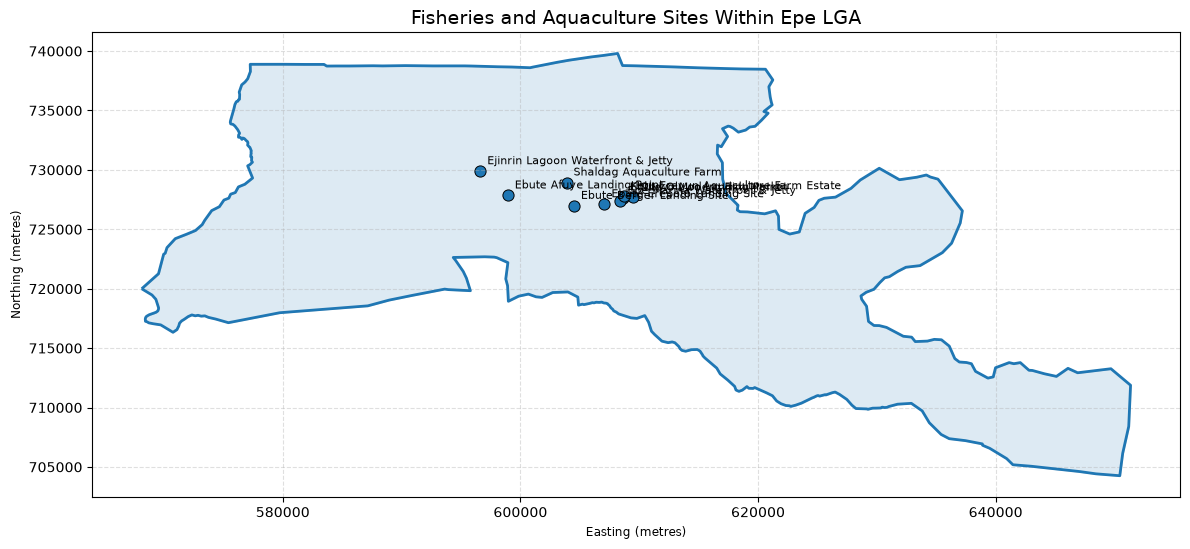

In [31]:

# CELL 29: MAP FISHERIES SITES WITHIN EPE LGA

import matplotlib.pyplot as plt
import geopandas as gpd
from pathlib import Path

# 1. Load the saved Epe LGA boundary.
boundary_path = (
    Path.cwd() / "data" / "processed" / "epe_lga_boundary.gpkg"
)

epe_boundary = gpd.read_file(boundary_path)

# 2. Match the boundary CRS to the fisheries point layer.
epe_boundary = epe_boundary.to_crs(spatial_data.crs)

# 3. Create the map.
fig, ax = plt.subplots(figsize=(12, 10))

# Draw the administrative boundary.
epe_boundary.boundary.plot(
    ax=ax,
    linewidth=2,
    label="Epe LGA boundary"
)

# Shade the area inside the boundary.
epe_boundary.plot(
    ax=ax,
    alpha=0.15,
    edgecolor="black"
)

# Draw all nine fisheries and aquaculture sites.
spatial_data.plot(
    ax=ax,
    markersize=65,
    edgecolor="black",
    linewidth=0.7,
    label="Fisheries and aquaculture sites"
)

# 4. Label each point with its site name.
for _, site in spatial_data.iterrows():
    ax.annotate(
        site["name"],
        xy=(site.geometry.x, site.geometry.y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# 5. Add map details.
ax.set_title(
    "Fisheries and Aquaculture Sites Within Epe LGA",
    fontsize=14
)
ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


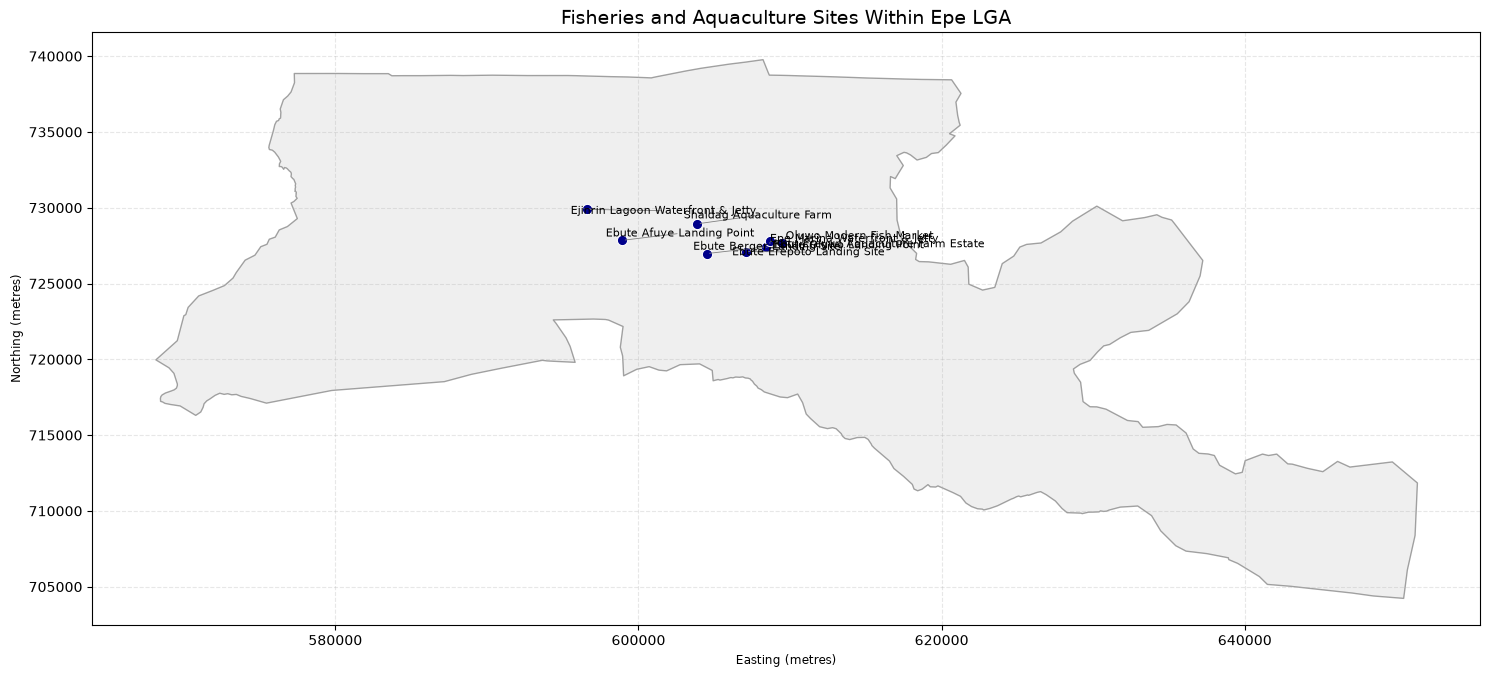

Map saved to: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\outputs\epe_fisheries_sites_map.png


In [33]:
\
# CELL 30: PLOT EPE LGA AND SITES WITH SEPARATED LABELS

import matplotlib.pyplot as plt
from pathlib import Path

fig, ax = plt.subplots(figsize=(15, 12))

# Draw the Epe LGA polygon.
epe_boundary.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="black",
    alpha=0.35
)

# Draw the fisheries and aquaculture points.
spatial_data.plot(
    ax=ax,
    markersize=55,
    color="darkblue",
    edgecolor="white",
    linewidth=0.8
)

# Manually position labels using offsets in map coordinates.
label_offsets = [
    (250, 250),
    (250, -350),
    (250, 350),
    (-900, -250),
    (-900, 250),
    (-900, 350),
    (250, -400),
    (-1100, 250),
    (-1100, -300)
]

for (_, site), (dx, dy) in zip(
    spatial_data.iterrows(), label_offsets
):
    ax.annotate(
        site["name"],
        xy=(site.geometry.x, site.geometry.y),
        xytext=(site.geometry.x + dx, site.geometry.y + dy),
        fontsize=8,
        arrowprops=dict(arrowstyle="-", color="grey", linewidth=0.6)
    )

ax.set_title(
    "Fisheries and Aquaculture Sites Within Epe LGA",
    fontsize=14
)
ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()

# Save the map.
map_path = Path.cwd() / "outputs" / "epe_fisheries_sites_map.png"
map_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(map_path, dpi=300, bbox_inches="tight")
plt.show()

print("Map saved to:", map_path)


In [34]:

# CELL 31: CREATE AN INTERACTIVE EPE FISHERIES MAP

import folium
from pathlib import Path

# Centre the map on the nine mapped sites.
center_lat = spatial_data["lat"].mean()
center_lon = spatial_data["lon"].mean()

interactive_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles="OpenStreetMap"
)

# Add the Epe LGA boundary.
folium.GeoJson(
    epe_boundary.to_crs("EPSG:4326").to_json(),
    name="Epe LGA boundary",
    style_function=lambda feature: {
        "color": "black",
        "weight": 2,
        "fillColor": "lightblue",
        "fillOpacity": 0.12
    },
    tooltip="Epe Local Government Area"
).add_to(interactive_map)

# Add the mapped fisheries and aquaculture locations.
for _, site in spatial_data.iterrows():
    popup_html = f"""
    <b>{site['name']}</b><br>
    Category: {site['category']}<br>
    Latitude: {site['lat']}<br>
    Longitude: {site['lon']}
    """

    folium.Marker(
        location=[site["lat"], site["lon"]],
        tooltip=site["name"],
        popup=folium.Popup(popup_html, max_width=300)
    ).add_to(interactive_map)

folium.LayerControl().add_to(interactive_map)

# Save the interactive map.
map_path = (
    Path.cwd() / "outputs" / "epe_fisheries_interactive_map.html"
)
map_path.parent.mkdir(parents=True, exist_ok=True)

interactive_map.save(str(map_path))

print("Interactive map saved to:", map_path)

interactive_map


Interactive map saved to: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\outputs\epe_fisheries_interactive_map.html


In [35]:

# CELL 32: CREATE THE COORDINATE-CONFIDENCE REGISTER

import pandas as pd
from pathlib import Path

# Start with the existing spatial inventory.
coordinate_register = spatial_data[
    ["name", "category", "lat", "lon", "evidence_tier", "source"]
].copy()

# Assign initial review statuses based on current evidence.
# These are provisional statuses, not claims of field verification.
coordinate_register["coordinate_confidence"] = "Unverified — review required"
coordinate_register["verification_method"] = "Not yet independently verified"
coordinate_register["review_notes"] = (
    "Point falls inside Epe LGA, but exact site position "
    "has not been independently confirmed."
)

# Flag the approximate coordinate already documented for this site.
approximate_sites = [
    "Ketu-Ereyun Aquaculture Farm Estate"
]

coordinate_register.loc[
    coordinate_register["name"].isin(approximate_sites),
    "coordinate_confidence"
] = "Approximate — verification required"

coordinate_register.loc[
    coordinate_register["name"].isin(approximate_sites),
    "review_notes"
] = (
    "Existing approximate coordinate; confirm the facility's "
    "actual location before treating it as verified."
)

# Display the register.
display(coordinate_register)

# Save the review register.
output_path = (
    Path.cwd()
    / "outputs"
    / "epe_coordinate_confidence_register.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

coordinate_register.to_csv(output_path, index=False)

print("\nRegister saved to:", output_path)
print("\nConfidence-status counts:")
print(coordinate_register["coordinate_confidence"].value_counts())


,name,category,lat,lon,evidence_tier,source,coordinate_confidence,verification_method,review_notes
0,Oluwo Modern Fish Market,Fish Market,6.582271,3.990089,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."
1,Ebute Oluwo Landing Point,Fish Landing Site,6.582260,3.982650,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."
2,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,6.579710,3.980740,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."
3,Ebute Erepoto Landing Site,Fish Landing Site,6.577180,3.968540,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."
4,Ebute Berger Landing Site,Fish Landing Site,6.575986,3.945330,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."
5,Shaldag Aquaculture Farm,Aquaculture Facility,6.593764,3.939745,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."
6,Ketu-Ereyun Aquaculture Farm Estate,Aquaculture Facility,6.583300,3.983300,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Approximate — verification required,Not yet independently verified,Existing approximate coordinate; confirm the f...
7,Ebute Afuye Landing Point,Fishing Activity Location,6.584000,3.895000,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."
8,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,6.602500,3.874100,Tier 2: Secondary / Mapped or Field Survey,OpenStreetMap / Secondary Reference,Unverified — review required,Not yet independently verified,"Point falls inside Epe LGA, but exact site pos..."



Register saved to: C:\Users\Lioness_eni\GitHub\epe-coastal-atlas\outputs\epe_coordinate_confidence_register.csv

Confidence-status counts:
coordinate_confidence
Unverified — review required           8
Approximate — verification required    1
Name: count, dtype: int64
